In [109]:
import torch
from sklearn.model_selection import train_test_split
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from helper_functions import plot_decision_boundary

In [110]:
X_blob, y_blob = make_blobs(n_samples=1000,
                            n_features=2,
                            centers=2,
                            cluster_std=0.8,
                            random_state=36)

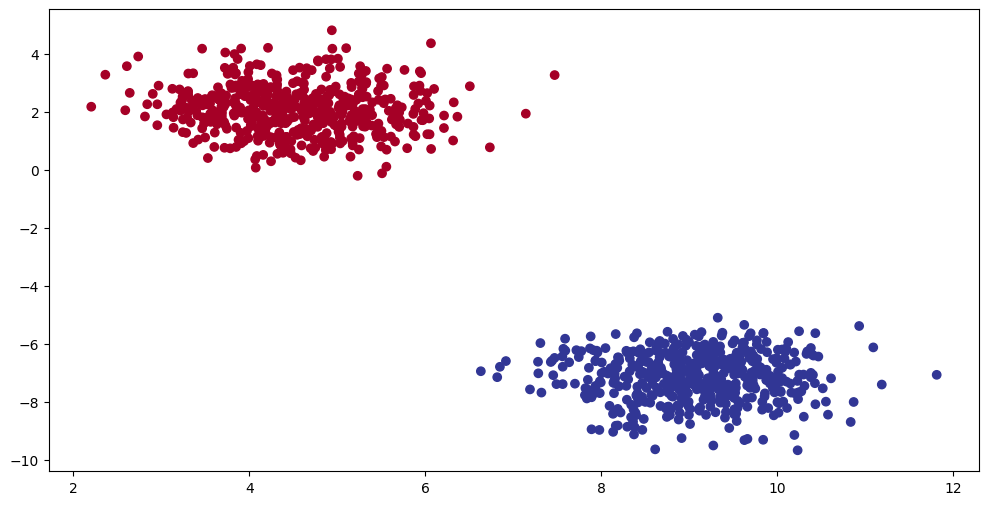

In [111]:
plt.figure(figsize=(12,6))
plt.scatter(X_blob[:,0], X_blob[:,1], c= y_blob, cmap = plt.cm.RdYlBu)

In [138]:
X_train, X_test , y_train, y_test = train_test_split(X_blob,
                                                     y_blob,
                                                     test_size = 0.2,
                                                     shuffle=True,
                                                     random_state=31)
X_train

tensor([[ 4.1823,  1.4022],
        [ 6.8167, -7.1538],
        [ 4.6215,  2.7540],
        ...,
        [ 6.7329,  0.7666],
        [ 5.0265,  1.2021],
        [ 4.1138,  1.8165]], dtype=torch.float64)

In [113]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [114]:
X_train = torch.from_numpy(X_train).to(device = device).type(torch.float)
X_test = torch.from_numpy(X_test).to(device = device).type(torch.float)
y_train= torch.from_numpy(y_train).to(device = device).type(torch.float)
y_test= torch.from_numpy(y_test).to(device = device).type(torch.float)

In [115]:
class LinearClassificationModelV0(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_layer_0 = nn.Linear(in_features=2,
                                        out_features=8)
        self.linear_layer_1 = nn.Linear(in_features= 8,
                                        out_features= 1)

    def forward(self, X):
        y = self.linear_layer_1(self.linear_layer_0(X))
        return y

In [116]:
torch.manual_seed(31)
model = LinearClassificationModelV0().to(device)

In [117]:
X_blob = torch.from_numpy(X_blob).to(device)
y_blob = torch.from_numpy(y_blob).to(device)

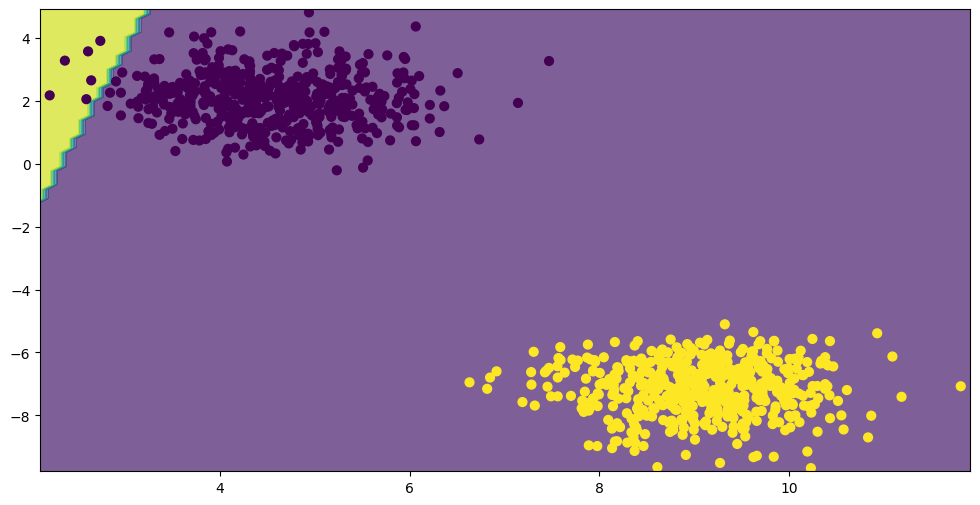

In [118]:
plt.figure(figsize=(12,6))
plot_decision_boundary(model, X_blob, y_blob)

In [119]:
loss_fn = nn.BCELoss()
optimizer = torch.optim.SGD(lr = 0.1,
                            params=model.parameters())

In [129]:
epochs = 1000
epoch_count = []
loss_values = []
test_loss_values = []

for epoch in range(epochs):
    model.train()

    y_logits = model(X_train)
    y_probs = torch.sigmoid(y_logits)
    y_preds = torch.round(y_probs)

    loss = loss_fn(y_probs, y_train.unsqueeze(1))

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()


    model.eval()
    with torch.inference_mode():
        y_test_logits  = model(X_test)
        y_test_probs = torch.sigmoid(y_test_logits)
        y_test_preds = torch.round(y_test_probs)

        test_loss = loss_fn(y_test_probs, y_test.unsqueeze(1))

    if epoch % 50 ==0:
        epoch_count.append(epoch)
        loss_values.append(loss)
        test_loss_values.append(test_loss)
        print(f"Epoch :{epoch} ! Loss : {loss} ! Test Loss : {test_loss}")

Epoch :0 ! Loss : 6.175232556415722e-05 ! Test Loss : 1.4729930626344867e-05
Epoch :50 ! Loss : 6.121851765783504e-05 ! Test Loss : 1.4560526324203238e-05
Epoch :100 ! Loss : 6.0692491388181224e-05 ! Test Loss : 1.439570405636914e-05
Epoch :150 ! Loss : 6.01769243075978e-05 ! Test Loss : 1.4230779015633743e-05
Epoch :200 ! Loss : 5.966807293589227e-05 ! Test Loss : 1.4071025361772627e-05
Epoch :250 ! Loss : 5.916852387599647e-05 ! Test Loss : 1.3915729141444899e-05
Epoch :300 ! Loss : 5.867677100468427e-05 ! Test Loss : 1.3762507478531916e-05
Epoch :350 ! Loss : 5.819381112814881e-05 ! Test Loss : 1.3612478142022155e-05
Epoch :400 ! Loss : 5.771653741248883e-05 ! Test Loss : 1.34608098960598e-05
Epoch :450 ! Loss : 5.7250887039117515e-05 ! Test Loss : 1.3313460840436164e-05
Epoch :500 ! Loss : 5.678776142303832e-05 ! Test Loss : 1.31726637846441e-05
Epoch :550 ! Loss : 5.633443652186543e-05 ! Test Loss : 1.3032507922616787e-05
Epoch :600 ! Loss : 5.588866406469606e-05 ! Test Loss : 1.2

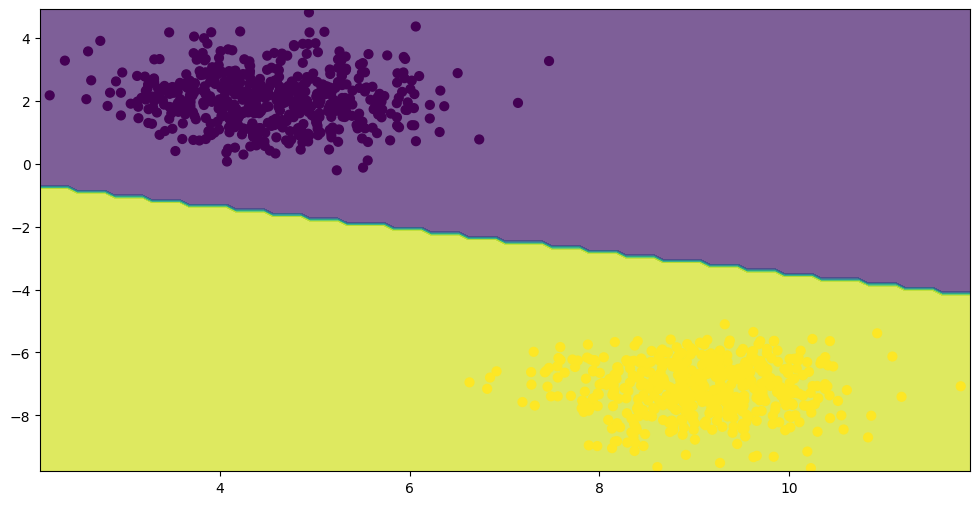

In [130]:
plt.figure(figsize=(12,6))
plot_decision_boundary(model, X_blob, y_blob)

In [142]:
y_logits = model(torch.tensor([6,6]).type(torch.float))
y = torch.round(torch.sigmoid(y_logits))
y

tensor([0.], grad_fn=<RoundBackward0>)